# Fields + NISAR frame map

Three panels: Arkansas with the frame footprints, the gauge cluster on imagery,
and a zoom on the tightly-packed Way 3 / Way 4 block.

**How this is organised.** Loading is slow (a 2.5 MB raster, the Natural Earth
shapefile, and web tiles); drawing is fast. So the loads are their own cells,
run once, and each panel is a *function* you can re-run on its own. Change
something in **Config**, re-run that cell and the one panel you care about, and
you get a preview in a second or two instead of rebuilding everything.

Order: run 1-6 once, then iterate on 7-11.

## 1. Imports

In [63]:
import warnings
warnings.filterwarnings("ignore")

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.img_tiles as cimgt
import cartopy.io.shapereader as shpreader
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from shapely.ops import unary_union

# Large type everywhere -- these figures get dropped into slides.
plt.rcParams.update({
    'font.size': 20, 'axes.titlesize': 20, 'axes.labelsize': 18,
    'xtick.labelsize': 15, 'ytick.labelsize': 15,
    'legend.fontsize': 12, 'legend.title_fontsize': 13, 'figure.titlesize': 28,
})
PC = ccrs.PlateCarree()
PROJ = ccrs.AlbersEqualArea(central_longitude=-92, central_latitude=34.5,
                            standard_parallels=(33, 36))
print("ready")

ready


## 2. Config — the only cell you normally need to touch

Everything cosmetic lives here. Re-run this plus a panel cell to see a change.

In [68]:
# ---- inputs ---------------------------------------------------------------
GAUGES_CSV = "data/2026_WaterLevel_Runkle/gauges_2026.csv"
INDEX_CSV  = "nisar_granule_index.csv"      # from nisar_coverage.py
COV_CSV    = "nisar_coverage_long.csv"      # which granules actually matter
RICE_TIF   = "data/downscaling_files/rice_mask_imi_2024.tif"
OUT_PNG    = "outputs/gauge_frame_map.png"

# ---- colours --------------------------------------------------------------
TRACK_COLOR = {12: "#e8702a", 84: "#1f77b4", 105: "#2ca02c"}  # add tracks here
DIR_STYLE   = {"DESC": "-", "ASC": "--"}
GAUGE_COLOR = "#d62728"
RICE_COLOR  = "#7fc97f"
ARK_COLOR   = "#333333"

# ---- panel 1: statewide ---------------------------------------------------
STATE_EXTENT = [-95.2, -88.6, 32.6, 36.9]     # lon_min, lon_max, lat_min, lat_max
FRAME_FILL_ALPHA = 0.13
FRAME_LINEWIDTH  = 2.6
# Where each track's label box sits, in lon/lat. Frames overlap heavily, so
# these are placed by hand rather than at the centroid.
LABEL_POS = {12: (-94.05, 35.72), 84: (-89.85, 35.55), 105: (-93.55, 33.15)}
LEGEND_LOC = "lower right"
RICE_STRIDE_STATE = 40      # plot every Nth rice pixel; lower = denser, slower

# ---- panel 2: gauge cluster ----------------------------------------------
CLUSTER_PAD = 0.09          # degrees of padding around the gauges
CLUSTER_TILE_ZOOM = 11      # higher = sharper + slower; 10-13 is sensible
# Label offsets in POINTS from each marker. The four Way fields are ~700 m
# apart, so without this they draw on top of each other.
CLUSTER_LABEL_OFFSET = {
    "S16": (42, 18), "R8": (-70, 18), "S0": (42, -10),
    "W3-EC": (58, 34), "W3-CS": (58, 8), "W4-EC": (58, -18), "W4-CS": (58, -44),
}

# ---- panel 3: Way block ---------------------------------------------------
WAY_PREFIX = "W"            # which gauge_ids belong to the zoom panel
WAY_PAD = 0.006
WAY_TILE_ZOOM = 15

# ---- figure ---------------------------------------------------------------
FIGSIZE = (30, 13)
DPI = 300
SUPTITLE = "2026 Fields and the NISAR passes that cover them"

## 3. Gauges

In [3]:
gauges = pd.read_csv(GAUGES_CSV)
print(f"{len(gauges)} gauges")
gauges

7 gauges


,gauge_id,lat,lon,field_name,acres,levees
0,W3-EC,34.58869,-91.75176,Way 3,71.0,No
1,W3-CS,34.58557,-91.75182,Way 3,71.0,No
2,W4-EC,34.58494,-91.75159,Way 4,72.0,No
3,W4-CS,34.58195,-91.75164,Way 4,72.0,No
4,S16,34.85023,-91.81026,S16,48.0,Contour
5,R8,34.84044,-91.86522,4 East,64.0,Straight
6,S0,34.49382,-91.76692,South 0,37.0,No


## 4. Frame footprints

One polygon per granule; granules from the same track/frame differ slightly, so
they get unioned per (track, frame, direction) when drawn.

In [11]:
idx = pd.read_csv(INDEX_CSV)
cov = pd.read_csv(COV_CSV)
keep = idx[idx.granule.isin(cov.granule.unique())]
frames = gpd.GeoDataFrame(keep, geometry=gpd.GeoSeries.from_wkt(keep.footprint_wkt),
                          crs=4326)
print(frames.groupby(["track", "frame", "direction"]).size().to_string())

track  frame  direction
12     71     DESC         15
84     71     DESC         14
105    19     ASC           9


## 5. State boundaries (Natural Earth, cached locally after first download)

In [4]:
_shp = shpreader.natural_earth(resolution="10m", category="cultural",
                               name="admin_1_states_provinces")
_recs = [r for r in shpreader.Reader(_shp).records()
         if r.attributes["admin"] == "United States of America"]
US_STATES = [r.geometry for r in _recs]
ARKANSAS  = [r.geometry for r in _recs if r.attributes["name"] == "Arkansas"]
print(f"{len(US_STATES)} states, Arkansas found: {len(ARKANSAS) == 1}")

51 states, Arkansas found: True


## 6. Rice mask as points

Scatter rather than imshow: the mask is UTM 15N and the panels are lon/lat, so
points reproject trivially while a raster would need warping. `RICE_STRIDE_STATE`
trades density for speed.

In [5]:
with rasterio.open(RICE_TIF) as src:
    arr, transform_, rice_crs = src.read(1), src.transform, src.crs
_rows, _cols = np.nonzero(arr == 1)
print(f"{_rows.size:,} rice pixels at {src.res[0]:.0f} m "
      f"= {_rows.size * (src.res[0] / 1000) ** 2:,.0f} km2")

def rice_points(stride):
    sl = slice(None, None, stride)
    xs, ys = rasterio.transform.xy(transform_, _rows[sl], _cols[sl])
    return gpd.GeoSeries(gpd.points_from_xy(xs, ys), crs=rice_crs).to_crs(4326)

rice_state = rice_points(RICE_STRIDE_STATE)
print(f"{len(rice_state):,} points for the statewide panel")

553,827 rice pixels at 120 m = 7,975 km2
13,846 points for the statewide panel


## 7. Imagery basemap helper

In [6]:
class EsriImagery(cimgt.GoogleTiles):
    """Esri World Imagery true-colour tiles. Note the {z}/{y}/{x} order."""
    def _image_url(self, tile):
        x, y, z = tile
        return ("https://server.arcgisonline.com/ArcGIS/rest/services/"
                f"World_Imagery/MapServer/tile/{z}/{y}/{x}")


def add_imagery(ax, zoom):
    """Imagery if the network allows, plain land if not -- never fail the figure."""
    try:
        ax.add_image(EsriImagery(), zoom)
        return True
    except Exception as err:
        print(f"tiles unavailable ({type(err).__name__}) - plain background")
        ax.add_feature(cfeature.LAND, facecolor="#f4f1ea")
        return False

## 8. Panel 1 — statewide

In [70]:
def panel_state(ax):
    ax.set_extent(STATE_EXTENT, crs=PC)
    ax.add_feature(cfeature.LAND, facecolor="#f4f1ea")
    ax.add_feature(cfeature.OCEAN, facecolor="#d6e6f0")
    ax.add_feature(cfeature.RIVERS, edgecolor="#8fb8d4", linewidth=0.7)
    ax.add_geometries(US_STATES, crs=PC, facecolor="none",
                      edgecolor="#b0b0b0", linewidth=0.9)
    ax.add_geometries(ARKANSAS, crs=PC, facecolor="none",
                      edgecolor=ARK_COLOR, linewidth=2.4, zorder=6)
    ax.scatter(rice_state.x, rice_state.y, s=1.2, c=RICE_COLOR, alpha=0.55,
               transform=PC, zorder=3)

    for (t, f, d), sub in frames.groupby(["track", "frame", "direction"]):
        poly = unary_union(list(sub.geometry))
        col = TRACK_COLOR.get(t, "#777777")
        ax.add_geometries([poly], crs=PC, facecolor=col,
                          alpha=FRAME_FILL_ALPHA, edgecolor="none", zorder=4)
        ax.add_geometries([poly], crs=PC, facecolor="none", edgecolor=col,
                          linewidth=FRAME_LINEWIDTH,
                          linestyle=DIR_STYLE[d], zorder=7)
        lx, ly = LABEL_POS.get(t, (poly.centroid.x, poly.bounds[3] - 0.2))
        ax.text(lx, ly, f"T{t} F{f} {d}\n{len(sub)} scenes", color=col,
                fontsize=16, fontweight="bold", ha="center", va="center",
                transform=PC, zorder=9,
                bbox=dict(fc="white", ec=col, alpha=0.92, boxstyle="round,pad=0.3"))

    ax.scatter(gauges.lon, gauges.lat, s=120, c=GAUGE_COLOR, edgecolor="white",
               linewidth=1.6, zorder=11, transform=PC)
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, color="gray",
                      alpha=0.35, linestyle=":")
    gl.top_labels = gl.right_labels = False
    ax.set_title("NISAR frames covering the 2026 Gauges")

    handles = [
        Line2D([0], [0], marker="o", color="none", markerfacecolor=GAUGE_COLOR,
               markeredgecolor="w", markersize=12, label=f"gauge ({len(gauges)} fields)"),
        Patch(facecolor=RICE_COLOR, alpha=.7, label="rice (2024 mask)"),
    ] + [
        Line2D([0], [0], color=TRACK_COLOR.get(t, "#777"), lw=FRAME_LINEWIDTH,
               ls=DIR_STYLE[d], label=f"track {t} / frame {f}  {d}")
        for (t, f, d) in sorted(frames.groupby(["track", "frame", "direction"]).groups)
    ] + [Line2D([0], [0], color=ARK_COLOR, lw=2.4, label="Arkansas")]
    ax.legend(handles=handles, loc=LEGEND_LOC, framealpha=0.95)

## 9. Panel 2 — gauge cluster

In [58]:
def panel_cluster(ax):
    ax.set_extent([gauges.lon.min() - CLUSTER_PAD, gauges.lon.max() + CLUSTER_PAD,
                   gauges.lat.min() - CLUSTER_PAD, gauges.lat.max() + CLUSTER_PAD],
                  crs=PC)
    add_imagery(ax, CLUSTER_TILE_ZOOM)
    ax.scatter(rice_state.x, rice_state.y, s=9, c=RICE_COLOR, alpha=0.8,
               transform=PC, zorder=3)
    for _, g in gauges.iterrows():
        ax.scatter(g.lon, g.lat, s=170, c=GAUGE_COLOR, edgecolor="white",
                   linewidth=2, zorder=11, transform=PC)
        ax.annotate(g.gauge_id, (g.lon, g.lat),
                    xytext=CLUSTER_LABEL_OFFSET.get(g.gauge_id, (10, 8)),
                    textcoords="offset points", fontsize=16, fontweight="bold",
                    color="white", zorder=12,
                    arrowprops=dict(arrowstyle="-", color="white", lw=1.2),
                    bbox=dict(fc=GAUGE_COLOR, ec="white", alpha=0.92,
                              boxstyle="round,pad=0.2"))
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, color="white",
                      alpha=0.4, linestyle=":")
    gl.top_labels = gl.right_labels = False
    ax.set_title("Gauge cluster — all 7 in the same frames")
    span = 111 * max(gauges.lat.max() - gauges.lat.min(),
                     (gauges.lon.max() - gauges.lon.min())
                     * np.cos(np.radians(gauges.lat.mean())))
    ax.text(0.02, 0.02, f"extent ≈ {span:.0f} km", transform=ax.transAxes,
            fontsize=12, color="white",
            bbox=dict(fc="black", alpha=0.55, boxstyle="round,pad=0.3"))

## 10. Panel 3 — Way 3 / Way 4 block

In [59]:
def panel_way(ax):
    way = gauges[gauges.gauge_id.str.startswith(WAY_PREFIX)]
    ax.set_extent([way.lon.min() - WAY_PAD, way.lon.max() + WAY_PAD,
                   way.lat.min() - WAY_PAD, way.lat.max() + WAY_PAD], crs=PC)
    add_imagery(ax, WAY_TILE_ZOOM)
    for _, g in way.iterrows():
        ax.scatter(g.lon, g.lat, s=240, c=GAUGE_COLOR, edgecolor="white",
                   linewidth=2.4, zorder=11, transform=PC)
        ax.annotate(f"{g.gauge_id}  ({g.field_name}, {g.acres:.0f} ac)",
                    (g.lon, g.lat), xytext=(14, 10), textcoords="offset points",
                    fontsize=16, fontweight="bold", color="white", zorder=12,
                    arrowprops=dict(arrowstyle="-", color="white", lw=1.4),
                    bbox=dict(fc=GAUGE_COLOR, ec="white", alpha=0.93,
                              boxstyle="round,pad=0.25"))
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, color="white",
                      alpha=0.4, linestyle=":")
    gl.top_labels = gl.right_labels = False
    ax.set_title("Way 3 / Way 4 block")
    dkm = 111 * (way.lat.max() - way.lat.min())
    ax.text(0.02, 0.02, f"these {len(way)} span ≈ {dkm:.1f} km",
            transform=ax.transAxes, fontsize=12, color="white",
            bbox=dict(fc="black", alpha=0.6, boxstyle="round,pad=0.3"))

## 11. Preview one panel

Fastest loop while tweaking: edit **Config**, re-run it, then run this with
whichever panel you are working on.

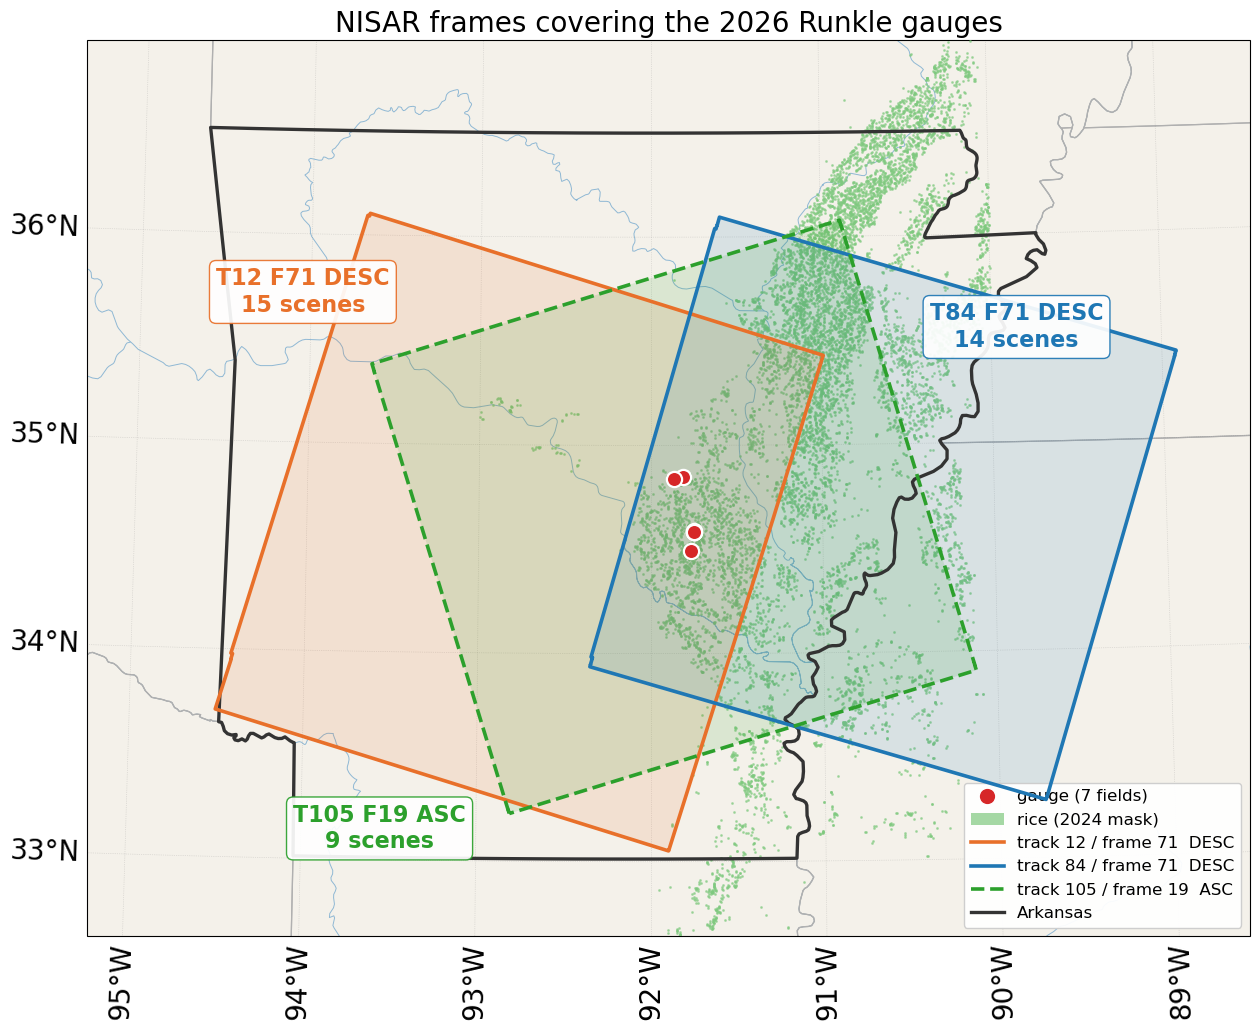

In [64]:
fig, ax = plt.subplots(figsize=(15, 12), subplot_kw={"projection": PROJ})
panel_state(ax)        # <- swap for panel_cluster / panel_way
plt.show()

## 12. Assemble and save

saved outputs/gauge_frame_map.png


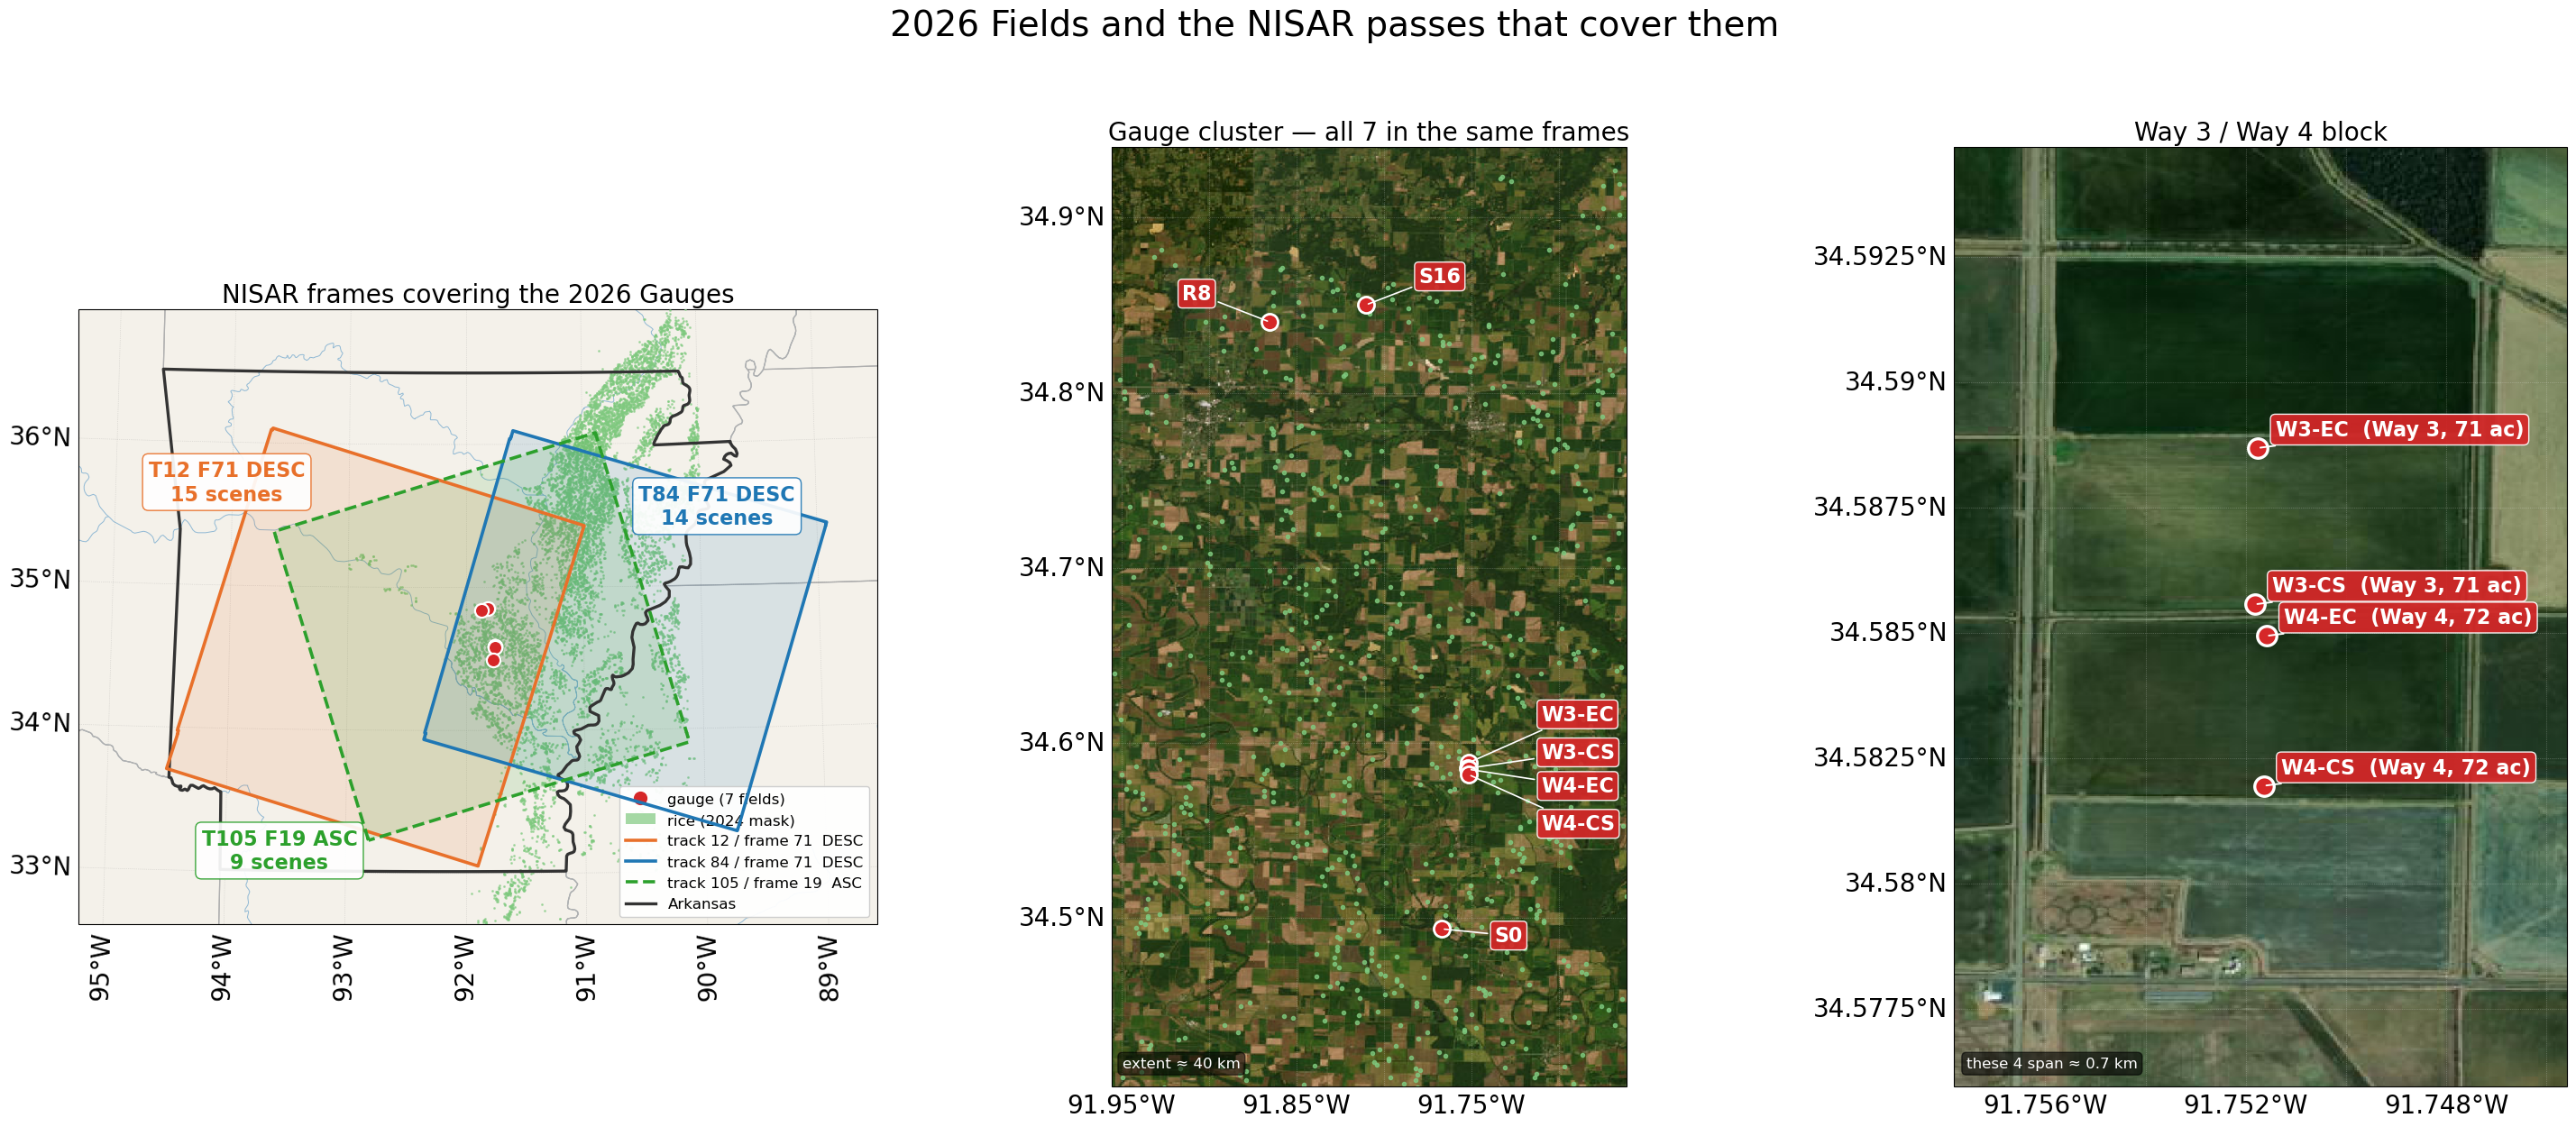

In [71]:
fig = plt.figure(figsize=FIGSIZE)
panel_state(fig.add_subplot(1, 3, 1, projection=PROJ))
panel_cluster(fig.add_subplot(1, 3, 2, projection=PC))
panel_way(fig.add_subplot(1, 3, 3, projection=PC))
fig.suptitle(SUPTITLE, y=0.97)
plt.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig(OUT_PNG, dpi=DPI, bbox_inches="tight")
print("saved", OUT_PNG)
plt.show()

## Changing things — quick reference

| want | change |
|---|---|
| different colour per track | `TRACK_COLOR` |
| add a track you later download | add it to `TRACK_COLOR`; everything else adapts |
| wider/narrower state view | `STATE_EXTENT` |
| a track label sits badly | `LABEL_POS[track] = (lon, lat)` |
| gauge labels collide | `CLUSTER_LABEL_OFFSET[id] = (dx, dy)` in points |
| sharper imagery | raise `CLUSTER_TILE_ZOOM` / `WAY_TILE_ZOOM` (slower) |
| denser rice stipple | lower `RICE_STRIDE_STATE`, re-run cell 6 |
| only descending frames | filter in cell 4: `frames = frames[frames.direction == "DESC"]` |
| drop the third panel | in cell 12 use `1, 2, n` and delete the `panel_way` line |

**Offline:** the tiles need network. Without it `add_imagery` prints a notice and
falls back to plain land, so panels 2 and 3 still render. Natural Earth and the
rice mask are local after the first run.